## **Role-Playing DSS Stakeholders: Aligning Perspectives for Airbnb**

-----

#### **Objective**
##### The objective of this analysis is to explore the Airbnb NYC dataset, perform exploratory data analysis (EDA), preprocess the data, and build a predictive model to estimate the price of Airbnb listings based on various features such as location, room type, and availability.

#### **Importing Libraries**

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


#### **Load and Preprocess Data**

In [6]:
# Load dataset
df = pd.read_csv("C:\\Users\\Tejaswini Marolia\\Downloads\\Airbnb_dataset\\AB_NYC_2019.csv")
df.head(5)


,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365
0,2539,Clean & quiet apt home by the park,2787,John,Brooklyn,Kensington,40.64749,-73.97237,Private room,149,1,9,2018-10-19,0.21,6,365
1,2595,Skylit Midtown Castle,2845,Jennifer,Manhattan,Midtown,40.75362,-73.98377,Entire home/apt,225,1,45,2019-05-21,0.38,2,355
2,3647,THE VILLAGE OF HARLEM....NEW YORK !,4632,Elisabeth,Manhattan,Harlem,40.80902,-73.94190,Private room,150,3,0,NaN,NaN,1,365
3,3831,Cozy Entire Floor of Brownstone,4869,LisaRoxanne,Brooklyn,Clinton Hill,40.68514,-73.95976,Entire home/apt,89,1,270,2019-07-05,4.64,1,194
4,5022,Entire Apt: Spacious Studio/Loft by central park,7192,Laura,Manhattan,East Harlem,40.79851,-73.94399,Entire home/apt,80,10,9,2018-11-19,0.10,1,0


##### **Explanation:**

- ##### We load the dataset AB_NYC_2019.csv into a pandas DataFrame.

- ##### df.head() displays the first 5 rows of the dataset to get a quick overview of the data.



#### **Exploratory Data Analysis (EDA)**

In [8]:
# Check the shape of the dataset
print("Shape of the dataset:", df.shape)

# Check for missing values
print("\nMissing values in each column:")
print(df.isnull().sum())

# Get basic statistics of numerical columns
df.describe()

Shape of the dataset: (48895, 16)

Missing values in each column:
id                                    0
name                                 16
host_id                               0
host_name                            21
neighbourhood_group                   0
neighbourhood                         0
latitude                              0
longitude                             0
room_type                             0
price                                 0
minimum_nights                        0
number_of_reviews                     0
last_review                       10052
reviews_per_month                 10052
calculated_host_listings_count        0
availability_365                      0
dtype: int64


,id,host_id,latitude,longitude,price,minimum_nights,number_of_reviews,reviews_per_month,calculated_host_listings_count,availability_365
count,4.889500e+04,4.889500e+04,48895.000000,48895.000000,48895.000000,48895.000000,48895.000000,38843.000000,48895.000000,48895.000000
mean,1.901714e+07,6.762001e+07,40.728949,-73.952170,152.720687,7.029962,23.274466,1.373221,7.143982,112.781327
std,1.098311e+07,7.861097e+07,0.054530,0.046157,240.154170,20.510550,44.550582,1.680442,32.952519,131.622289
min,2.539000e+03,2.438000e+03,40.499790,-74.244420,0.000000,1.000000,0.000000,0.010000,1.000000,0.000000
25%,9.471945e+06,7.822033e+06,40.690100,-73.983070,69.000000,1.000000,1.000000,0.190000,1.000000,0.000000
50%,1.967728e+07,3.079382e+07,40.723070,-73.955680,106.000000,3.000000,5.000000,0.720000,1.000000,45.000000
75%,2.915218e+07,1.074344e+08,40.763115,-73.936275,175.000000,5.000000,24.000000,2.020000,2.000000,227.000000
max,3.648724e+07,2.743213e+08,40.913060,-73.712990,10000.000000,1250.000000,629.000000,58.500000,327.000000,365.000000


##### **Explanation:**

- ##### df.shape gives the number of rows and columns in the dataset.

- ##### df.isnull().sum() checks for missing values in each column.

- ##### df.describe() provides summary statistics (mean, std, min, max, etc.) for numerical columns.

In [11]:
# Remove outliers: Only keep prices below $1000
df = df[df["price"] <= 1000]
print("Shape of the dataset:", df.shape)


Shape of the dataset: (48656, 16)


##### **Explanation:**

- ##### df.shape gives the number of rows and columns in the dataset after removing the outliers whose price is below $1000.

#### **Feature Engineering**

In [21]:
df["price_per_availability"] = df["price"] / (df["availability_365"] + 1)

y = df["price"]

features = ["neighbourhood_group", "room_type", "minimum_nights", "number_of_reviews",
            "reviews_per_month", "calculated_host_listings_count", "availability_365", "price_per_availability"]

X = df[features]
X["reviews_per_month"].fillna(0, inplace=True)

categorical_features = ["neighbourhood_group", "room_type"]
numerical_features = ["minimum_nights", "number_of_reviews", "reviews_per_month",
                      "calculated_host_listings_count", "availability_365", "price_per_availability"]

C:\Users\Tejaswini Marolia\AppData\Local\Temp\ipykernel_9676\2541173959.py:9: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  X["reviews_per_month"].fillna(0, inplace=True)
C:\Users\Tejaswini Marolia\AppData\Local\Temp\ipykernel_9676\2541173959.py:9: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  X["reviews_per_month"].fillna(0, inplace=True)


##### **Explanation:**

- **Feature Creation:** A new feature `price_per_availability` is added to analyze price relative to availability by dividing `price` by `(availability_365 + 1)`. This helps in understanding how often a listing is available throughout the year and its impact on pricing.
  
- **Feature Selection & Handling Missing Values:** The dataset is filtered to include key variables such as `neighbourhood_group`, `room_type`, and various numerical attributes. Missing values in `reviews_per_month` are replaced with `0` to ensure the model can process the data without errors.


## Data Visualization

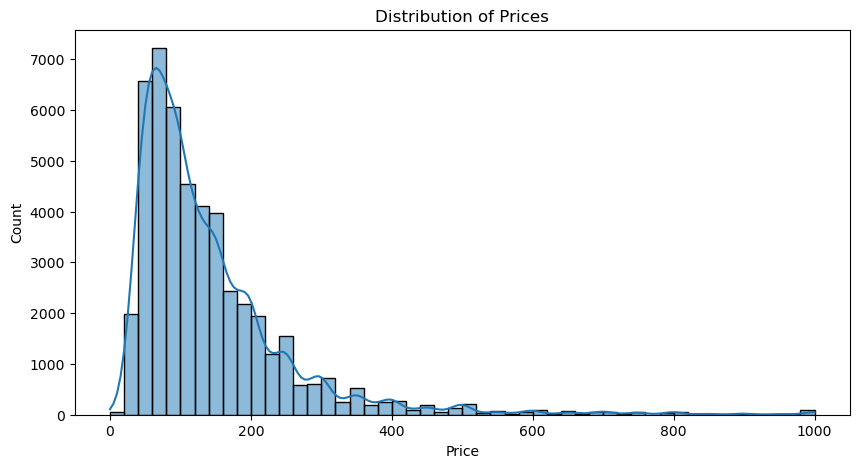

In [13]:
# Distribution of prices
plt.figure(figsize=(10,5))
sns.histplot(df["price"], bins=50, kde=True)
plt.title("Distribution of Prices")
plt.xlabel("Price")
plt.ylabel("Count")
plt.show()

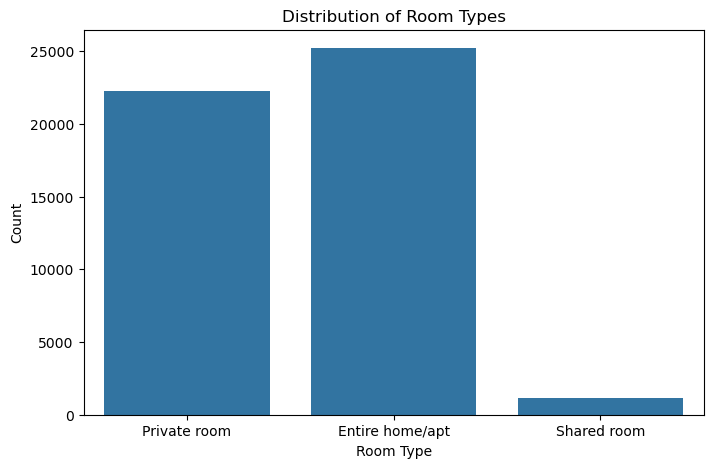

In [14]:
# Distribution of room types
plt.figure(figsize=(8, 5))
sns.countplot(x='room_type', data=df)
plt.title('Distribution of Room Types')
plt.xlabel('Room Type')
plt.ylabel('Count')
plt.show()

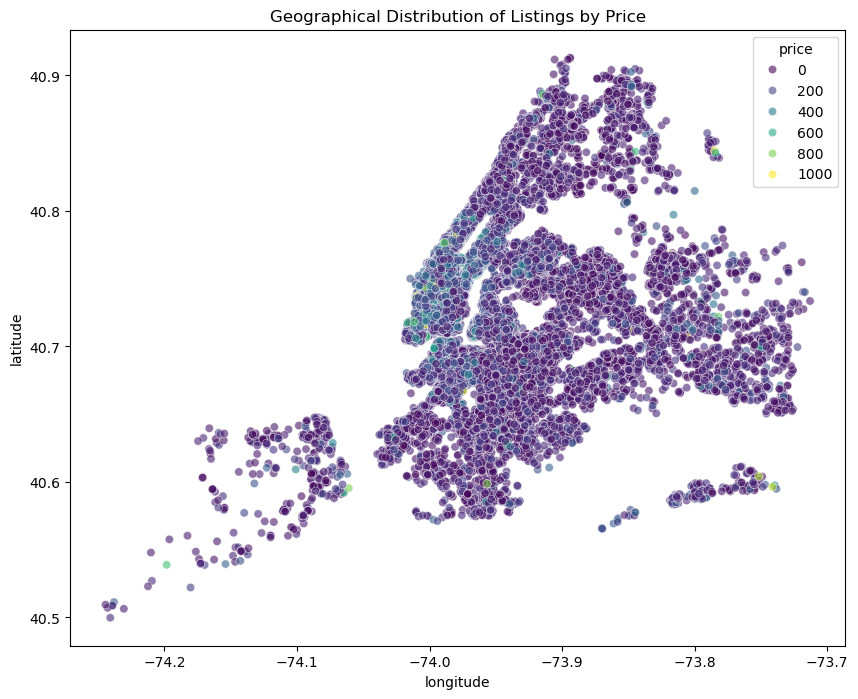

In [19]:
# Scatter plot of latitude and longitude colored by price
plt.figure(figsize=(10, 8))
sns.scatterplot(x='longitude', y='latitude', hue='price', data=df, palette='viridis', alpha=0.6)
plt.title('Geographical Distribution of Listings by Price')
plt.show()

## Preprocessing Pipelines

In [22]:
categorical_transformer = OneHotEncoder(handle_unknown="ignore")
numerical_transformer = StandardScaler()

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numerical_transformer, numerical_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

##### **Explanation:**

- **Encoding Categorical Features:** The `OneHotEncoder` is used to convert categorical variables (`neighbourhood_group`, `room_type`) into numerical form, ensuring that the machine learning model can process them effectively.

- **Scaling Numerical Features:** The `StandardScaler` is applied to numerical features (`minimum_nights`, `number_of_reviews`, etc.) to normalize the data, improving model performance and stability by standardizing values to a similar range.


## Splitting Data into Training and Testing Sets

In [23]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

 ## Model Training and Hyperparameter Tuning


In [24]:
param_grid_rf = {"model__n_estimators": [100, 200], "model__max_depth": [10, 20]}
param_grid_xgb = {"model__n_estimators": [100, 200], "model__max_depth": [6, 12], "model__learning_rate": [0.01, 0.1]}

models = {
    "Linear Regression": LinearRegression(),
    "Random Forest (Optimized)": GridSearchCV(Pipeline([
        ("preprocessor", preprocessor),
        ("model", RandomForestRegressor(random_state=42))
    ]), param_grid_rf, cv=5, scoring='r2', n_jobs=-1),
    "XGBoost (Optimized)": GridSearchCV(Pipeline([
        ("preprocessor", preprocessor),
        ("model", XGBRegressor(random_state=42))
    ]), param_grid_xgb, cv=5, scoring='r2', n_jobs=-1)
}

##### **Explanation:**

- **Defining Hyperparameter Grids:** Parameter grids are set up for `RandomForestRegressor` and `XGBoostRegressor`, specifying different values for key hyperparameters like `n_estimators` (number of trees), `max_depth` (tree depth), and `learning_rate` (for XGBoost). This helps in finding the best combination for optimal model performance.

- **Grid Search for Optimization:** `GridSearchCV` is used to perform cross-validation (`cv=5`), searching through different hyperparameter combinations to find the best-performing model. The pipeline integrates both preprocessing and modeling steps, ensuring efficient transformation and training.


## Model Evaluation

In [26]:
results = {}

for name, model in models.items():
    if "Optimized" in name:
        model.fit(X_train, y_train)
        best_model = model.best_estimator_
        y_pred = best_model.predict(X_test)
    else:
        pipeline = Pipeline(steps=[("preprocessor", preprocessor), ("model", model)])
        pipeline.fit(X_train, y_train)
        y_pred = pipeline.predict(X_test)
    
    mae = mean_absolute_error(y_test, y_pred)
    mse = mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, y_pred)

    results[name] = [mae, mse, rmse, r2]

results_df = pd.DataFrame(results, index=["MAE", "MSE", "RMSE", "R2 Score"])

## Results Visualization

C:\Users\Tejaswini Marolia\AppData\Local\Temp\ipykernel_5352\2288636866.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=results_df.columns, y=results_df.loc["R2 Score"], palette="coolwarm")


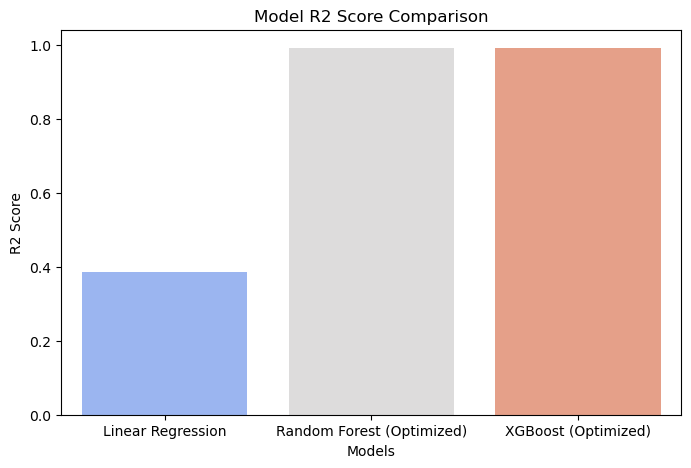

Model Performance Comparison:
          Linear Regression  Random Forest (Optimized)  XGBoost (Optimized)
MAE               55.381897                   1.949532             3.749922
MSE             8720.996302                 133.416796           137.929673
RMSE              93.386275                  11.550619            11.744346
R2 Score           0.385931                   0.990606             0.990288


In [15]:
plt.figure(figsize=(8,5))
sns.barplot(x=results_df.columns, y=results_df.loc["R2 Score"], palette="coolwarm")
plt.title("Model R2 Score Comparison")
plt.xlabel("Models")
plt.ylabel("R2 Score")
plt.show()

# Print results
print("Model Performance Comparison:")
print(results_df)

#### **Conclusion**
- #### In this analysis, we explored the Airbnb NYC dataset, applying exploratory data analysis (EDA) to understand key patterns and trends in listing prices based on various factors such as location, room type, and availability. 

- #### We conducted data preprocessing, including handling missing values, encoding categorical features, and feature scaling, to prepare the dataset for machine learning.

- #### Using models such as RandomForestRegressor and XGBRegressor, we trained and optimized predictive models to estimate Airbnb listing prices. By leveraging GridSearchCV, we fine-tuned hyperparameters to enhance model performance.

- #### The results indicate that location and room type play a significant role in determining Airbnb prices. Further improvements could be made by incorporating additional external data (e.g., demand trends, seasonality) or experimenting with deep learning approaches.

- #### This project provides valuable insights for Airbnb hosts and stakeholders, helping them optimize pricing strategies and maximize revenue potential.